# 🧠 Análisis de Sentimiento en Reseñas de Clientes

**Cliente:** WeLoveReviews — una consultora que ayuda a empresas a entender la opinión real de sus clientes.

**Pregunta de negocio:** Un negocio tiene una puntuación promedio de **4.5 / 5 estrellas**, pero la account manager quiere saber:  
*¿El sentimiento expresado en las reseñas escritas realmente coincide con esa calificación?*

**Enfoque:** Usaremos un modelo preentrenado de Hugging Face (`nlptown/bert-base-multilingual-uncased-sentiment`) para clasificar el sentimiento de ~500 reseñas y comparar la distribución obtenida con el promedio de 4.5 estrellas. Identificaremos falsos negativos debidos al desajuste de dominio (modelo entrenado en reseñas de productos, aplicado a reseñas de servicios).

**Flujo del notebook:**
1. Exploración y análisis de datos (EDA)
2. Plan de acción y justificación del modelo
3. Inferencia del modelo sobre las 500 reseñas
4. Comparación de distribución de sentimiento vs promedio de estrellas
5. Análisis de falsos negativos
6. Revisión manual de predicciones
7. Conclusiones para la account manager

In [15]:
# ──────────────────────────────────────────────
# 1. Cargar librerías y configurar entorno
# ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import sys

warnings.filterwarnings('ignore')

# Estilo de gráficos
plt.style.use('ggplot')
sns.set_palette('Set2')

print(f"Python version: {sys.version}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

%matplotlib inline

Python version: 3.13.16 (main, Oct  6 2026, 04:38:44) [GCC 14.2.0]
Pandas version: 3.0.6
NumPy version: 2.5.4


## 2. Exploración de Datos (EDA)

In [16]:
# ──────────────────────────────────────────────
# Cargar el dataset de reseñas
# ──────────────────────────────────────────────

DATA_PATH = '../data/raw/reviews.csv'
df = pd.read_csv(DATA_PATH)

print(f"Dimensiones del dataset: {df.shape}")
print(f"\nColumnas: {list(df.columns)}")
df.head(3)

Dimensiones del dataset: (500, 3)

Columnas: ['review_id', 'rating', 'review_text']


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...


In [17]:
# ──────────────────────────────────────────────
# Información general del dataset
# ──────────────────────────────────────────────

print("=== Información del DataFrame ===")
df.info()

print("\n=== Estadísticas descriptivas ===")
df.describe()

=== Información del DataFrame ===
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    500 non-null    int64
 1   rating       500 non-null    int64
 2   review_text  500 non-null    str  
dtypes: int64(2), str(1)
memory usage: 11.8 KB

=== Estadísticas descriptivas ===


,review_id,rating
count,500.000000,500.000000
mean,250.500000,4.500000
std,144.481833,0.952794
min,1.000000,1.000000
25%,125.750000,4.000000
50%,250.500000,5.000000
75%,375.250000,5.000000
max,500.000000,5.000000


Distribución de calificaciones:
rating
1     12
2     18
3     38
4     72
5    360
Name: count, dtype: int64


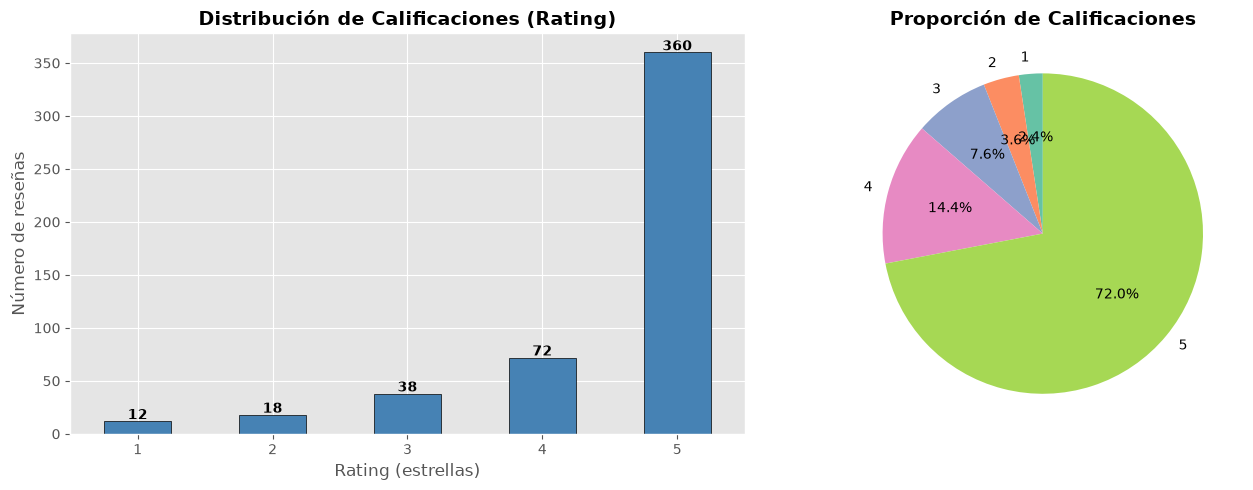


Promedio de calificaciones: 4.50 ⭐
Mediana: 5.00 ⭐
Moda: 5 ⭐


In [18]:
# ──────────────────────────────────────────────
# Distribución de calificaciones (rating)
# ──────────────────────────────────────────────

rating_counts = df['rating'].value_counts().sort_index()
print("Distribución de calificaciones:")
print(rating_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de barras
rating_counts.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Distribución de Calificaciones (Rating)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Rating (estrellas)')
axes[0].set_ylabel('Número de reseñas')
axes[0].tick_params(axis='x', rotation=0)

# Añadir etiquetas en las barras
for i, v in enumerate(rating_counts.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# Gráfico de pastel
rating_counts.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90, 
                   colors=sns.color_palette('Set2', len(rating_counts)))
axes[1].set_title('Proporción de Calificaciones', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print(f"\nPromedio de calificaciones: {df['rating'].mean():.2f} ⭐")
print(f"Mediana: {df['rating'].median():.2f} ⭐")
print(f"Moda: {df['rating'].mode()[0]:.0f} ⭐")

Estadísticas de longitud de reseñas (caracteres):
count    500.0
mean     170.2
std       27.1
min       86.0
25%      155.0
50%      173.0
75%      189.0
max      230.0
Name: review_length, dtype: float64

Estadísticas de conteo de palabras:
count    500.0
mean      29.1
std        4.8
min       14.0
25%       26.0
50%       29.0
75%       32.0
max       42.0
Name: word_count, dtype: float64


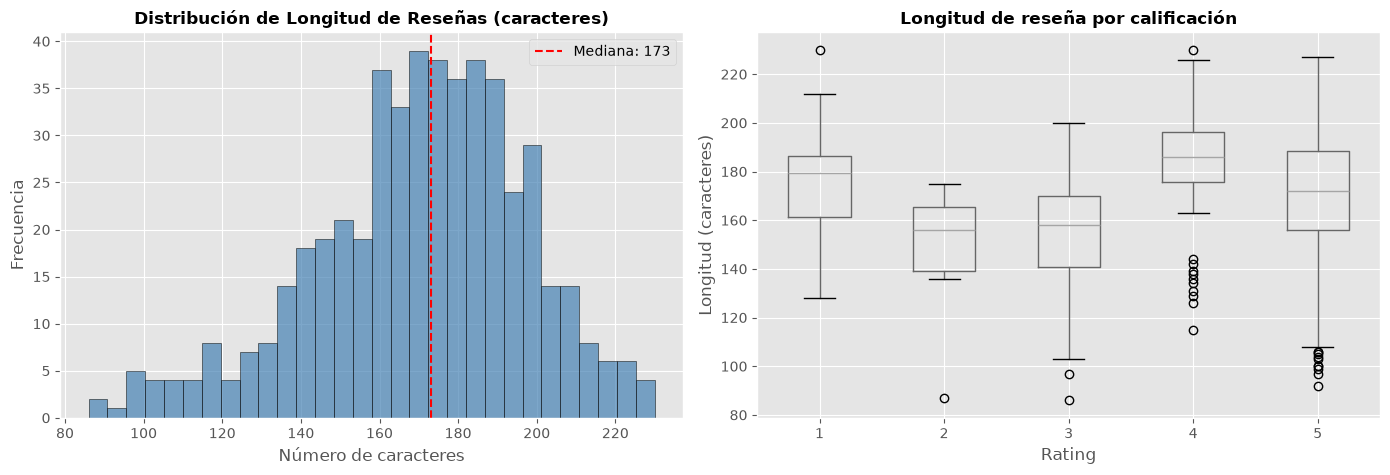

In [19]:
# ──────────────────────────────────────────────
# Análisis de la longitud de las reseñas
# ──────────────────────────────────────────────

df['review_length'] = df['review_text'].str.len()
df['word_count'] = df['review_text'].str.split().str.len()

print("Estadísticas de longitud de reseñas (caracteres):")
print(df['review_length'].describe().round(1))

print("\nEstadísticas de conteo de palabras:")
print(df['word_count'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de longitud
axes[0].hist(df['review_length'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].axvline(df['review_length'].median(), color='red', linestyle='--', 
                label=f"Mediana: {df['review_length'].median():.0f}")
axes[0].set_title('Distribución de Longitud de Reseñas (caracteres)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Número de caracteres')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# Boxplot por rating
df.boxplot(column='review_length', by='rating', ax=axes[1])
axes[1].set_title('Longitud de reseña por calificación', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Longitud (caracteres)')

plt.suptitle('')
plt.tight_layout()
plt.show()

In [20]:
# ──────────────────────────────────────────────
# Muestras de reseñas por calificación
# ──────────────────────────────────────────────

print("=" * 60)
print("MUESTRAS DE RESEÑAS POR CALIFICACIÓN")
print("=" * 60)

for rating in sorted(df['rating'].unique()):
    muestras = df[df['rating'] == rating]['review_text'].head(2).tolist()
    print(f"\n{'─' * 50}")
    print(f"⭐ {rating} estrella(s) — {len(df[df['rating'] == rating])} reseñas")
    print(f"{'─' * 50}")
    for i, m in enumerate(muestras, 1):
        print(f"  [{i}] {m[:200]}...")
        print()

MUESTRAS DE RESEÑAS POR CALIFICACIÓN

──────────────────────────────────────────────────
⭐ 1 estrella(s) — 12 reseñas
──────────────────────────────────────────────────
  [1] Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning....

  [2] Came to Harbor House Café for a birthday brunch. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning....


──────────────────────────────────────────────────
⭐ 2 estrella(s) — 18 reseñas
──────────────────────────────────────────────────
  [1] Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning....

  [2] Stopped by Harbor House Café for the first time. The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning....


──────────────────────────

In [21]:
# ──────────────────────────────────────────────
# Nulos y duplicados
# ──────────────────────────────────────────────

print("Valores nulos por columna:")
print(df.isnull().sum())

print(f"\nReseñas duplicadas (review_id duplicados): {df['review_id'].duplicated().sum()}")
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")

# Verificar si hay textos vacíos
empty_texts = df['review_text'].isna().sum() + (df['review_text'].str.strip() == '').sum()
print(f"Reseñas con texto vacío o nulo: {empty_texts}")

Valores nulos por columna:
review_id        0
rating           0
review_text      0
review_length    0
word_count       0
dtype: int64

Reseñas duplicadas (review_id duplicados): 0
Filas duplicadas exactas: 0
Reseñas con texto vacío o nulo: 0


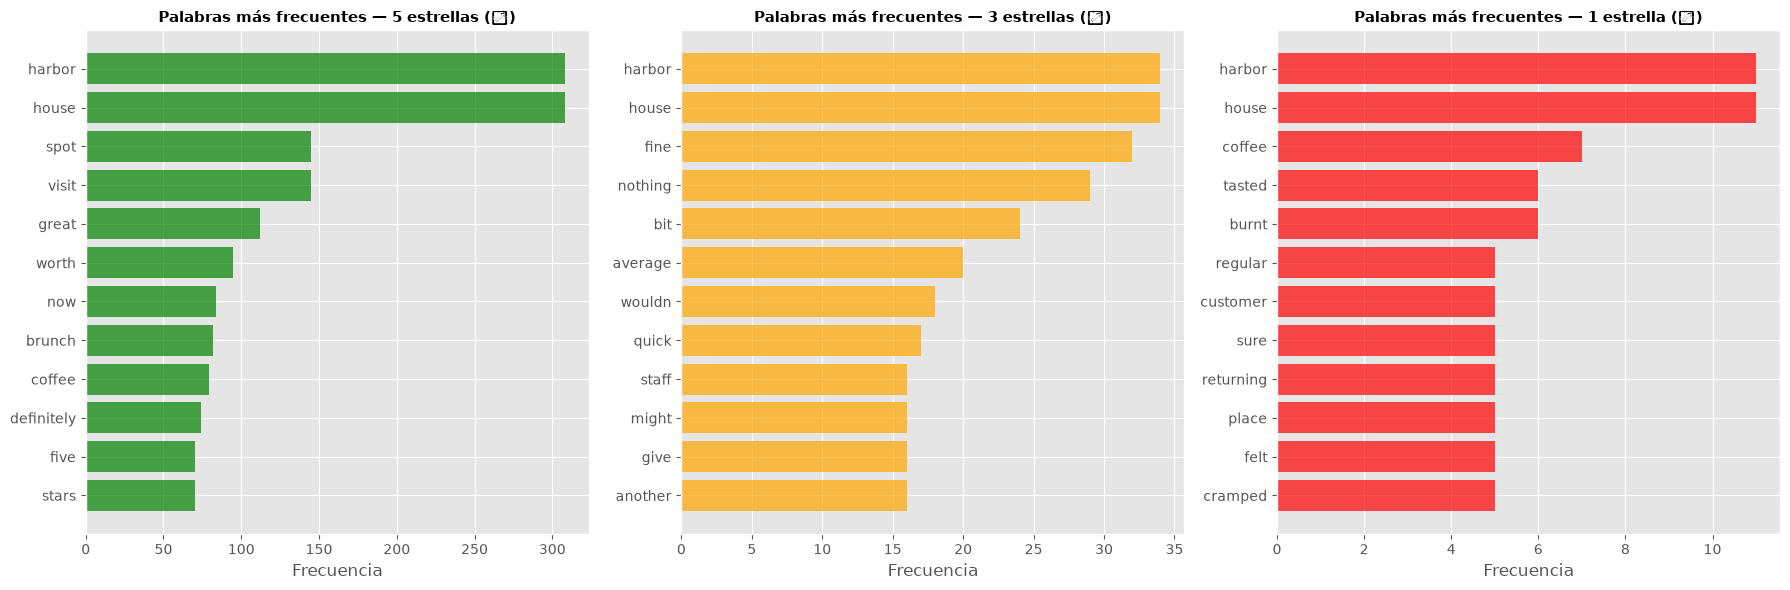

In [22]:
# ──────────────────────────────────────────────
# Análisis de palabras más frecuentes por rating
# ──────────────────────────────────────────────

from collections import Counter
import re

def get_common_words(text_series, n=15, stop_words=None):
    """Extrae las palabras más comunes de una serie de textos."""
    if stop_words is None:
        stop_words = {'the', 'a', 'an', 'and', 'or', 'but', 'in', 'on', 'at', 'to', 'for',
                      'of', 'with', 'by', 'from', 'is', 'it', 'as', 'be', 'has', 'have',
                      'i', 'my', 'me', 'we', 'our', 'you', 'your', 'he', 'she', 'they',
                      'this', 'that', 'was', 'were', 'been', 'are', 'had', 'did', 'not',
                      'no', 'so', 'if', 'all', 'just', 'very', 'too', 'really', 'also',
                      'its', 'but', 'what', 'which', 'who', 'when', 'where', 'how',
                      'more', 'some', 'any', 'each', 'every', 'their', 'them', 'his',
                      'her', 'about', 'out', 'up', 'do', 'does', 'done', 'got', 'get',
                      'am', 'im', 'ive', 'dont', 'isnt', 'cant', 'wont', 'it\'s',
                      'theres', 'theres', 'been', 'being', 'would', 'could', 'should',
                      'there', 'here', 'then', 'than', 'into', 'over', 'after', 'before',
                      'will', 'can', 'hasnt', 'hadnt', 'didnt', 'doesnt', 'wasnt',
                      'were', 'werent', 'lets', 'thats', 'thatll', 'youre', 'youve',
                      'theyre', 'theyve', 'hes', 'shes', 'theyr', 'because', 'while',
                      'since', 'until', 'during', 'through', 'against', 'between',
                      'under', 'again', 'further', 'once', 'almost', 'enough', 'even',
                      'much', 'many', 'most', 'other', 'such', 'only', 'own', 'same',
                      'than', 'too', 'very', 'way', 'well', 'like', 'back', 'still',
                      'around', 'off', 'down', 'these', 'those'}

    all_text = ' '.join(text_series.dropna().str.lower()).replace('\n', ' ')
    words = re.findall(r'\b[a-z]+\b', all_text)
    filtered = [w for w in words if w not in stop_words and len(w) > 2]
    return Counter(filtered).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

ratings_to_plot = [(5, '5 estrellas (⭐)', 'green'), 
                   (3, '3 estrellas (⭐)', 'orange'),
                   (1, '1 estrella (⭐)', 'red')]

for idx, (rating, title, color) in enumerate(ratings_to_plot):
    subset = df[df['rating'] == rating]['review_text']
    common = get_common_words(subset, n=12)
    words, counts = zip(*common)
    axes[idx].barh(list(reversed(words)), list(reversed(counts)), color=color, alpha=0.7)
    axes[idx].set_title(f'Palabras más frecuentes — {title}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Frecuencia')

plt.tight_layout()
plt.show()

### Insights del EDA

**Hallazgos observados en las 500 reseñas:**

1. **Ratings positivos mayoritarios:** 360 reseñas tienen 5 estrellas y 72 tienen 4; en total, 432 (86.4%) son positivas según la escala de estrellas. Hay 38 reseñas neutrales (7.6%) y 30 negativas (6.0%). El promedio es 4.50.
2. **Datos completos:** no se encontraron valores nulos, textos vacíos, IDs duplicados ni filas exactamente duplicadas.
3. **Longitud acotada:** las reseñas tienen entre 86 y 230 caracteres; la mediana es 173 caracteres. El promedio es de 29 palabras.
4. **Vocabulario:** las reseñas de 5 estrellas repiten términos como *spot*, *visit* y *great*; las de 3 estrellas incluyen *fine*, *average* y *nothing*; las de 1 estrella incluyen *coffee*, *burnt* y *returning*. El nombre del local también aparece con mucha frecuencia, así que estas frecuencias unigramas son descriptivas y no capturan por sí solas el contexto o la negación.

**Implicación:** el promedio de 4.50 resume las calificaciones, pero no valida por sí mismo el sentimiento del texto. Compararemos el modelo con los ratings como referencia imperfecta y revisaremos discrepancias concretas.

## 3. Plan de Acción y Justificación del Modelo

### Modelo seleccionado
Usaremos **`nlptown/bert-base-multilingual-uncased-sentiment`** de Hugging Face.

**¿Por qué este modelo?**
- Es un modelo BERT multilingüe fine-tuneado específicamente para análisis de sentimiento en 5 niveles (1 a 5 estrellas).
- Su salida coincide directamente con nuestra escala de calificación, lo que facilita la comparación.
- A pesar del desajuste de dominio (entrenado en reseñas de productos como Amazon), es el punto de partida ideal.

**Mapeo de sentimiento:**
| Predicción del modelo | Banda de sentimiento |
|:---------------------:|:--------------------:|
| 1–2 estrellas | Negativo |
| 3 estrellas | Neutral |
| 4–5 estrellas | Positivo |

**⚠️ Desajuste de dominio conocido:** El modelo fue fine-tuneado sobre reseñas de productos. Nuestro dataset contiene reseñas de servicios (restaurantes/cafeterías) — los clientes hablan del personal, tiempos de espera y ambiente. Esto puede producir falsos negativos: reseñas que a un humano leen como positivas pero el modelo clasifica con bajo sentimiento.

**Reglas de integración:**
1. Cargar el modelo una sola vez con `pipeline()` antes del loop de inferencia.
2. Fijar el nombre del modelo (no depender de `"latest"`).
3. No subir los pesos del modelo al repositorio.

In [23]:
# ──────────────────────────────────────────────
# 4. Cargar modelo preentrenado (una sola vez)
# ──────────────────────────────────────────────

from transformers import pipeline

# Modelo fijado (pinned) — no depende de "latest"
MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"

print(f"Cargando modelo: {MODEL_NAME}")
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME
)
print("✅ Modelo cargado exitosamente.")

Cargando modelo: nlptown/bert-base-multilingual-uncased-sentiment


Device set to use cpu


✅ Modelo cargado exitosamente.


In [24]:
# ──────────────────────────────────────────────
# 5. Inferencia sobre las 500 reseñas
# ──────────────────────────────────────────────

from tqdm.notebook import tqdm

def predict_sentiment(text):
    """
    Predice el sentimiento de un texto.
    Retorna: (label_raw, score, stars, sentiment_band)
    """
    result = sentiment_pipeline(text[:512])[0]  # Truncar a 512 tokens
    label = result['label']
    score = result['score']
    
    # El modelo devuelve etiquetas como "1 star", "2 stars", ..., "5 stars"
    stars = int(label.split()[0])
    
    # Mapeo a bandas de sentimiento
    if stars <= 2:
        band = "Negativo"
    elif stars == 3:
        band = "Neutral"
    else:
        band = "Positivo"
    
    return label, score, stars, band

# Aplicar inferencia a todas las reseñas
print("Procesando 500 reseñas con el modelo...")
results = []
for i, text in enumerate(tqdm(df['review_text'], total=len(df))):
    results.append(predict_sentiment(text))

# Expandir resultados en columnas
df[['pred_label', 'pred_score', 'pred_stars', 'sentiment_band']] = pd.DataFrame(
    results, index=df.index
)

print("✅ Inferencia completada.")
df[['review_id', 'rating', 'pred_stars', 'sentiment_band', 'pred_score']].head(10)

Procesando 500 reseñas con el modelo...


  0%|          | 0/500 [00:00<?, ?it/s]

✅ Inferencia completada.


,review_id,rating,pred_stars,sentiment_band,pred_score
0,1,5,5,Positivo,0.716958
1,2,5,5,Positivo,0.982220
2,3,5,5,Positivo,0.662323
3,4,5,5,Positivo,0.989547
4,5,5,5,Positivo,0.982912
5,6,5,5,Positivo,0.333903
6,7,5,5,Positivo,0.798027
7,8,5,5,Positivo,0.823738
8,9,3,3,Neutral,0.646990
9,10,5,5,Positivo,0.575618


In [25]:
# ──────────────────────────────────────────────
# 6. Comparación: Distribución del modelo vs realidad
# ──────────────────────────────────────────────

print("=" * 60)
print("DISTRIBUCIÓN DE SENTIMIENTO SEGÚN EL MODELO")
print("=" * 60)

band_counts = df['sentiment_band'].value_counts()
total = len(df)

for band in ['Positivo', 'Neutral', 'Negativo']:
    count = band_counts.get(band, 0)
    pct = count / total * 100
    print(f"  {band}: {count} reseñas ({pct:.1f}%)")

print(f"\nDistribución real de calificaciones (rating promedio: {df['rating'].mean():.2f}):")
real_pos = len(df[df['rating'] >= 4])
real_neu = len(df[df['rating'] == 3])
real_neg = len(df[df['rating'] <= 2])
print(f"  Positivo (4-5⭐): {real_pos} ({real_pos/total*100:.1f}%)")
print(f"  Neutral (3⭐): {real_neu} ({real_neu/total*100:.1f}%)")
print(f"  Negativo (1-2⭐): {real_neg} ({real_neg/total*100:.1f}%)")

# Matriz de comparación
print("\n" + "=" * 60)
print("MATRIZ: Rating real vs Predicción del modelo")
print("=" * 60)
comparison = pd.crosstab(
    df['rating'].map({1: '1⭐', 2: '2⭐', 3: '3⭐', 4: '4⭐', 5: '5⭐'}),
    df['pred_stars'].map({1: '1⭐', 2: '2⭐', 3: '3⭐', 4: '4⭐', 5: '5⭐'}),
    margins=True
)
exact_matches = (df['rating'] == df['pred_stars']).sum()
print(f"Coincidencia exacta de estrellas: {exact_matches}/{total} ({exact_matches/total*100:.1f}%)")
comparison

DISTRIBUCIÓN DE SENTIMIENTO SEGÚN EL MODELO
  Positivo: 412 reseñas (82.4%)
  Neutral: 41 reseñas (8.2%)
  Negativo: 47 reseñas (9.4%)

Distribución real de calificaciones (rating promedio: 4.50):
  Positivo (4-5⭐): 432 (86.4%)
  Neutral (3⭐): 38 (7.6%)
  Negativo (1-2⭐): 30 (6.0%)

MATRIZ: Rating real vs Predicción del modelo
Coincidencia exacta de estrellas: 429/500 (85.8%)


pred_stars,1⭐,2⭐,3⭐,4⭐,5⭐,All
rating,,,,,,
1⭐,3,9,0,0,0,12
2⭐,7,9,2,0,0,18
3⭐,0,3,35,0,0,38
4⭐,1,0,3,47,21,72
5⭐,11,4,1,9,335,360
All,22,25,41,56,356,500


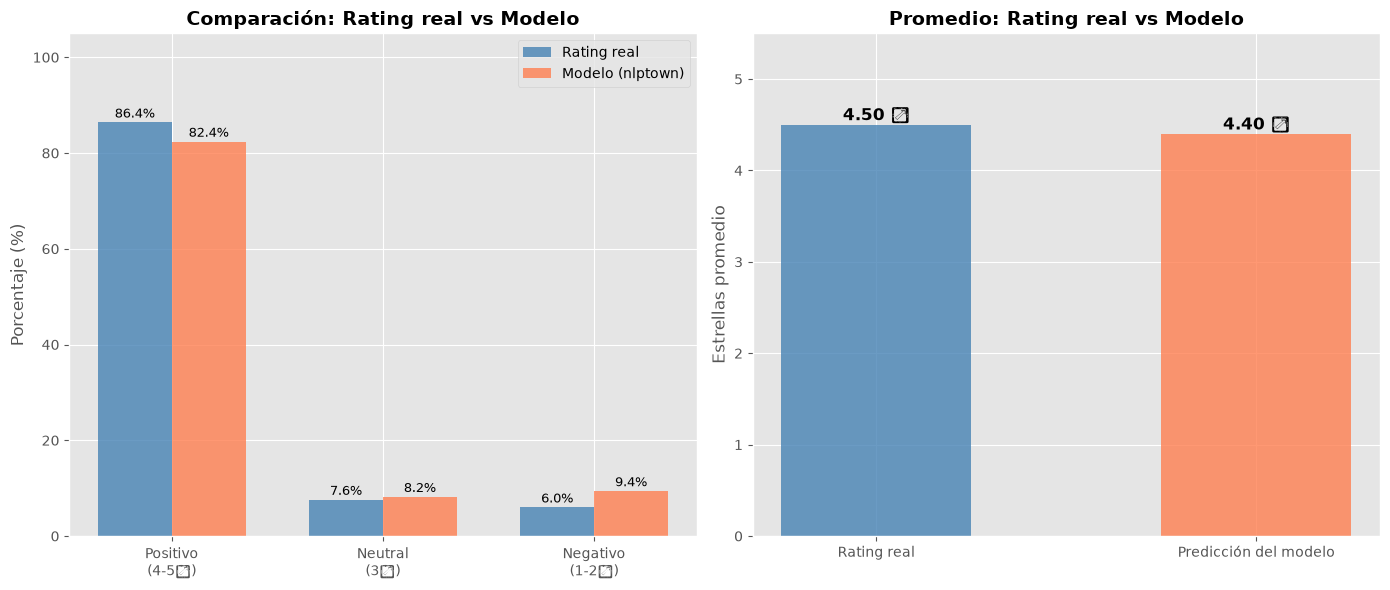

📊 Diferencia: 0.10 estrellas


In [26]:
# ──────────────────────────────────────────────
# Visualización de la comparación
# ──────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Distribución real (rating) vs Distribución del modelo
labels_bands = ['Positivo\n(4-5⭐)', 'Neutral\n(3⭐)', 'Negativo\n(1-2⭐)']
real_dist = [
    len(df[df['rating'] >= 4]) / total * 100,
    len(df[df['rating'] == 3]) / total * 100,
    len(df[df['rating'] <= 2]) / total * 100
]
model_dist = [
    band_counts.get('Positivo', 0) / total * 100,
    band_counts.get('Neutral', 0) / total * 100,
    band_counts.get('Negativo', 0) / total * 100
]

x = np.arange(len(labels_bands))
width = 0.35

axes[0].bar(x - width/2, real_dist, width, label='Rating real', color='steelblue', alpha=0.8)
axes[0].bar(x + width/2, model_dist, width, label='Modelo (nlptown)', color='coral', alpha=0.8)
axes[0].set_ylabel('Porcentaje (%)')
axes[0].set_title('Comparación: Rating real vs Modelo', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels_bands)
axes[0].legend()
axes[0].set_ylim(0, 105)

# Añadir etiquetas
for i in range(3):
    axes[0].text(i - width/2, real_dist[i] + 1, f'{real_dist[i]:.1f}%', ha='center', fontsize=9)
    axes[0].text(i + width/2, model_dist[i] + 1, f'{model_dist[i]:.1f}%', ha='center', fontsize=9)

# Gráfico 2: Calificación promedio real vs Predicha
avg_real = df['rating'].mean()
avg_pred = df['pred_stars'].mean()

bars = axes[1].bar(['Rating real', 'Predicción del modelo'], [avg_real, avg_pred], 
                   color=['steelblue', 'coral'], alpha=0.8, width=0.5)
axes[1].set_ylabel('Estrellas promedio')
axes[1].set_title('Promedio: Rating real vs Modelo', fontsize=14, fontweight='bold')
axes[1].set_ylim(0, 5.5)

# Añadir etiquetas con valores
for bar, val in zip(bars, [avg_real, avg_pred]):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, 
                f'{val:.2f} ⭐', ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

print(f"📊 Diferencia: {avg_real - avg_pred:.2f} estrellas")

### Interpretación de la comparación

En estas 500 reseñas, el rating real clasifica 86.4% como positivo, 7.6% como neutral y 6.0% como negativo. El modelo clasifica 82.4% como positivo, 8.2% como neutral y 9.4% como negativo.

El promedio predicho es **4.40 estrellas**, frente a **4.50 reales** (diferencia de **0.10 estrellas**). La distribución es parecida, pero el modelo desplaza 4.0 puntos porcentuales desde positivo y añade 3.4 puntos al grupo negativo. Esto es una señal de subestimación moderada, no evidencia de que todas las discrepancias se deban exclusivamente al dominio.

Los ratings son una referencia útil, pero no una etiqueta independiente del sentimiento textual; por eso no interpretamos esta comparación como una medición definitiva de exactitud.

In [27]:
# ──────────────────────────────────────────────
# 7. Análisis de Falsos Negativos
# ──────────────────────────────────────────────

# Falsos negativos: modelo predice 1-2⭐ pero rating real es 4-5⭐
false_negatives = df[(df['rating'] >= 4) & (df['pred_stars'] <= 2)]
# Falsos positivos: modelo predice 4-5⭐ pero rating real es 1-2⭐
false_positives = df[(df['rating'] <= 2) & (df['pred_stars'] >= 4)]

print("=" * 60)
print("FALSOS NEGATIVOS (Rating alto, modelo predice bajo)")
print("=" * 60)
print(f"Cantidad: {len(false_negatives)} reseñas")
print(f"Porcentaje del total: {len(false_negatives)/len(df)*100:.1f}%")
print(f"Porcentaje de reseñas positivas reales: {len(false_negatives)/len(df[df['rating']>=4])*100:.1f}%")

if len(false_negatives) > 0:
    print(f"\nLas {min(5, len(false_negatives))} más extremas (pred_stars más baja):")
    display(false_negatives.nsmallest(min(5, len(false_negatives)), 'pred_stars')[
        ['review_id', 'rating', 'pred_stars', 'pred_score', 'review_text']
    ])

print(f"\n{'=' * 60}")
print("FALSOS POSITIVOS (Rating bajo, modelo predice alto)")
print("=" * 60)
print(f"Cantidad: {len(false_positives)} reseñas")

if len(false_positives) > 0:
    display(false_positives[['review_id', 'rating', 'pred_stars', 'pred_score', 'review_text']].head(5))

FALSOS NEGATIVOS (Rating alto, modelo predice bajo)
Cantidad: 16 reseñas
Porcentaje del total: 3.2%
Porcentaje de reseñas positivas reales: 3.7%

Las 5 más extremas (pred_stars más baja):


,review_id,rating,pred_stars,pred_score,review_text
13,14,4,1,0.444348,Tried Harbor House Café after seeing it recomm...
14,15,5,1,0.389345,Every dish was bursting with flavor. The place...
72,73,5,1,0.267875,Stopped by Harbor House Café for the first tim...
86,87,5,1,0.324705,Tried Harbor House Café after seeing it recomm...
203,204,5,1,0.349168,Came to Harbor House Café for a birthday brunc...



FALSOS POSITIVOS (Rating bajo, modelo predice alto)
Cantidad: 0 reseñas


### Análisis de discrepancias

El modelo asigna 1–2 estrellas a **16 reseñas** cuyo rating real es 4–5: son el **3.7%** de las 432 reseñas con rating positivo y el 3.2% del total. No hubo casos con rating 1–2 que el modelo clasificara como 4–5.

En la muestra aparecen ejemplos de rating alto con texto explícitamente favorable que el modelo asigna a 1 estrella, como reseñas que dicen que los platos tenían mucho sabor o describen un ambiente acogedor y una próxima visita. Estos casos muestran errores relevantes para el negocio. El desajuste entre reseñas de producto y de servicios es una explicación plausible, pero esta comparación por sí sola no demuestra causalidad.

La matriz también muestra discrepancias de un nivel (por ejemplo, ratings 4 predichos como 5). Debemos distinguir estos errores de escala de una inversión real del sentimiento.

In [29]:
# ──────────────────────────────────────────────
# 8. Muestra para inspección manual (15-20 reseñas)
# ──────────────────────────────────────────────

# Muestra ratings coincidentes por clase y los falsos negativos más severos.
matching = (
    df[df['rating'] == df['pred_stars']]
    .groupby('rating', group_keys=False)
    .head(2)
    .copy()
)
matching['sample_type'] = 'Coincidencia exacta'

false_negatives_sample = (
    df[(df['rating'] >= 4) & (df['pred_stars'] <= 2)]
    .sort_values(['pred_stars', 'pred_score'])
    .head(6)
    .copy()
)
false_negatives_sample['sample_type'] = 'Rating positivo / modelo negativo'

manual_sample = (
    pd.concat([matching, false_negatives_sample])
    .drop_duplicates(subset='review_id')
    .sort_values(['sample_type', 'rating', 'review_id'])
)

print(f"Reseñas seleccionadas para inspección manual: {len(manual_sample)}")
with pd.option_context('display.max_colwidth', None):
    display(manual_sample[
        ['review_id', 'sample_type', 'rating', 'pred_stars', 'sentiment_band', 'pred_score', 'review_text']
    ].reset_index(drop=True))

Reseñas seleccionadas para inspección manual: 16


,review_id,sample_type,rating,pred_stars,sentiment_band,pred_score,review_text
0,107,Coincidencia exacta,1,1,Negativo,0.552520,Tried Harbor House Café after seeing it recommended online. The coffee tasted burnt. We waited 25 minutes just to get water. Expected a lot more given the reviews.
1,140,Coincidencia exacta,1,1,Negativo,0.507203,The coffee tasted burnt. We waited 25 minutes just to get water. The place felt cramped and chaotic. Not sure I'll be returning.
2,47,Coincidencia exacta,2,2,Negativo,0.523914,Came to Harbor House Café for a birthday brunch. The portions were way too small for the price. Our server got our order wrong twice. Probably won't recommend it to friends.
3,115,Coincidencia exacta,2,2,Negativo,0.624875,Grabbed a quick coffee at Harbor House Café this morning. The pastry was stale. We waited 25 minutes just to get water. Disappointing experience overall.
4,9,Coincidencia exacta,3,3,Neutral,0.646990,"Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop."
5,16,Coincidencia exacta,3,3,Neutral,0.505683,Stopped by Harbor House Café for the first time. The menu is fine but a bit repetitive. The cashier was rude when i asked about the menu. Might give it another shot.
6,19,Coincidencia exacta,4,4,Positivo,0.715694,"Regular customer at Harbor House Café here. The pastries were incredible. The staff were polite but a bit slow, but overall a solid experience. Might give it another shot."
7,21,Coincidencia exacta,4,4,Positivo,0.656825,"The coffee was rich and perfectly brewed. The staff were polite but a bit slow, but overall a solid experience. This is now my go-to spot."
8,1,Coincidencia exacta,5,5,Positivo,0.716958,Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
9,2,Coincidencia exacta,5,5,Positivo,0.982220,Tried Harbor House Café after seeing it recommended online. The coffee was rich and perfectly brewed. Great spot to work or catch up with friends. Great value for what you get. Five stars without hesitation.


### Resultado de la inspección cualitativa

En los seis falsos negativos seleccionados, los ratings son de 5 estrellas y el modelo predice 1. Los textos describen servicio rápido y amable, atención a alergias, platos sabrosos o intención de volver; uno incluye además una queja puntual sobre el cajero, pero termina con una valoración global favorable. Esto ilustra cómo una queja local puede pesar más que el tono general y por qué conviene revisar el texto completo.

Los ejemplos coincidentes también son coherentes en extremos: las reseñas de 1–2 estrellas mencionan café quemado, esperas, porciones pequeñas o pedidos incorrectos, mientras las de 4–5 estrellas seleccionadas describen comida y servicio favorables. La muestra se construyó deliberadamente para incluir falsos negativos, por lo que no es representativa ni debe usarse para calcular una tasa de exactitud humana.

## 9. Conclusiones para la Account Manager

**Resumen ejecutivo:**

- Las 500 reseñas tienen un promedio de **4.50 estrellas**. Por rating, 86.4% son positivas (4–5 estrellas), 7.6% neutrales y 6.0% negativas.
- El modelo devuelve 82.4% positivas, 8.2% neutrales y 9.4% negativas, con un promedio de **4.40 estrellas**. En conjunto, apunta a una experiencia mayormente positiva, aunque es algo más negativo que los ratings: 0.10 estrellas menos y 4.0 puntos porcentuales menos en la banda positiva.
- La predicción coincide exactamente con el rating en **429 de 500 casos (85.8%)**. Esta es concordancia con la calificación, no exactitud medida contra etiquetas humanas de sentimiento.
- **16 de las 432 reseñas con rating 4–5 (3.7%)** fueron clasificadas como negativas por el modelo; no hubo ratings 1–2 clasificados como positivos. La inspección cualitativa confirma que hay algunos falsos negativos con texto claramente favorable.

**Recomendación:** comunicar que la señal general del texto es consistente con una experiencia positiva, pero que el modelo muestra una pequeña tendencia a la negatividad y falla en algunos casos importantes. Usar el análisis como complemento, revisar discrepancias antes de escalar casos y no automatizar decisiones con este modelo sin validarlo con reseñas de servicios etiquetadas por personas. Para mejorar, reunir una muestra representativa y etiquetada del dominio y evaluar o ajustar el modelo con ella.

**Limitación:** los ratings son una referencia imperfecta para el sentimiento expresado en texto; además, la muestra de inspección es cualitativa y pequeña. Los resultados no prueban por sí solos que el desajuste de dominio sea la causa de cada error.